# EAM Potential

The example below illustrates how to perform molecular dynamics simulations with the `Amardus MD engine` using an EAM potential.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ase import Atoms as AseAtoms
from ase.build import bulk
from ase.md.velocitydistribution import (
    MaxwellBoltzmannDistribution,
    Stationary,
)
from amardus import BANNER, Atoms, System, Simulation
from amardus.parameters import get_default_unit
from amardus.reporters import StateReporter, XyzReporter, CSVReporter
from amardus.integration import VerletIntegrator
from amardus.coupling import BrendsenThermostat, BrendsenBarostat
from amardus.potentials import EAMPotential, EAMParams

## Preparing the simulation

In [2]:
unit = get_default_unit()
time_step = 0.001 * unit.picoseconds
cutoff = 5.3 * unit.angstrom 
temperature = 300.0 * unit.kelvin
pressure = 1.0 * unit.bar
thermostat_coupling_time = 10 * time_step
barostat_coupling_time = 100 * time_step

atoms_ase: AseAtoms = bulk('Cu', 'fcc', a=3.615 + 0.2, cubic=True).repeat((6, 6, 6))
MaxwellBoltzmannDistribution(
    atoms_ase,
    temperature_K=temperature / unit.kelvin,
    rng=np.random.default_rng(1234),
)
Stationary(atoms_ase)
atom_types_map = {"Cu": 0}
atoms = Atoms.from_ase(atoms_ase, atom_types_map)

cu_prams = EAMParams(
    A=0.391865 * unit.electronvolt * unit.angstrom**-1,
    d=4.32 * unit.angstrom,
    c=4.29 * unit.angstrom,
    c0=10.18724 * unit.electronvolt * unit.angstrom**-2,
    c1=-12.82033 * unit.electronvolt * unit.angstrom**-3,
    c2=6.176587 * unit.electronvolt * unit.angstrom**-4,
    c3=-1.341391 * unit.electronvolt * unit.angstrom**-5,
    c4=0.109842 * unit.electronvolt * unit.angstrom**-6,
    B=-0.881096 * unit.angstrom**-2,
)
eam = EAMPotential(
    cutoff_radius=cutoff, 
    params=cu_prams,
)

system = System.create(
    atoms,
    neighbor_cutoff=cutoff,
    neighbor_skin=2.0 * unit.angstrom,
    neighbor_max_atoms=300,
)

themorstat = BrendsenThermostat(temperature, thermostat_coupling_time)
barostat = BrendsenBarostat(
        pressure, 
        barostat_coupling_time, 
        interval=1, 
        compressibility= 1.0 / (1.484e6 * unit.bar),
)
verlet = VerletIntegrator(
    time_step=time_step,
    system_couplings=[
        themorstat,
        barostat,
    ],
)

state = StateReporter(interval=1000)
xyz = XyzReporter("cu.xyz", atom_types_map, interval=1000)
csv = CSVReporter("thermo-cu.csv", interval=500)

simulation = Simulation(
    system,
    verlet,
    forcefields=[eam],
    reporters=[state, xyz, csv],
)
print(BANNER)
print(simulation)


      _                            _
     / \   _ __ ___   __ _ _ __ __| |_   _ ___
    / _ \ | '_ ` _ \ / _` | '__/ _` | | | / __|
   / ___ \| | | | | | (_| | | | (_| | |_| \__ \
  /_/   \_\_| |_| |_|\__,_|_|  \__,_|\__,_|___/
           Molecular Dynamics Engine
-------------------------------------------------
Simulation(system=System(num_atoms=864), integration=VerletIntegrator(time_step=0.0982269, system_couplings=[BrendsenThermostat(target_temperature=300.0, coupling_time=0.9822690000000001, interval=1), BrendsenBarostat(target_pressure=6.2415e-07, coupling_time=9.822690000000001, compressibility=1.079635420074266, interval=1)]), forcefields=[EAMPotential(cutoff_radius=5.3)], reporters=[StateReporter(interval=1000), XyzReporter(interval=1000), CSVReporter(interval=500)])


## Equilibration simulation

Use the following command to run the benchmark LAMMPS simulation
```bash
pixi run lmp < in.eam
```

In [3]:
%%time 

simulation.step()
simulation.step(10_000)

Step     Temp           Press          PotEng         KinEng         TotEng         AvgNgh         Density       
0        309.48533852   -94691.59550559 -2915.40564786 34.56355945    -2880.84208841 134.00000000   7.60175267    
1000     296.18734589   587.25413779   -2975.89293168 33.07842945    -2942.81450223 131.02083333   8.78069800    
2000     305.03876377   161.81549619   -2979.96732333 34.06696258    -2945.90036075 130.91203704   8.79121797    
3000     300.05564815   788.63881859   -2978.77818119 33.51044441    -2945.26773678 131.09027778   8.79855704    
4000     299.79743423   387.67056738   -2980.21745000 33.48160688    -2946.73584311 130.92592593   8.79831844    
5000     297.77178765   413.34059301   -2979.77106582 33.25538112    -2946.51568469 131.03240741   8.79794869    
6000     298.80710552   196.00634377   -2979.71896590 33.37100622    -2946.34795968 130.88888889   8.79700748    
7000     297.80029845   577.86940655   -2978.28011196 33.25856523    -2945.02154673 131

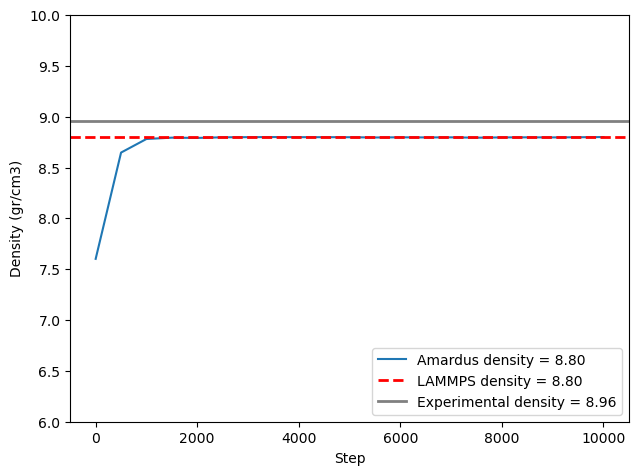

In [4]:
df = pd.read_csv("thermo-cu.csv")

ax = df.plot(
    x="Step",
    y="Density",
    # figsize=(8, 6),
    label=f"Amardus density = {df['Density'][-10:].mean():.2f}",
)

# Experimental melting temperature of Cu (K)
rho_exp = 8.96 
rho_lammps =  8.80

ax.axhline(
    y=rho_lammps,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"LAMMPS density = {rho_lammps:.2f}"
)
ax.axhline(
    y=rho_exp,
    color="gray",
    linestyle="-",
    linewidth=2,
    label=f"Experimental density = {rho_exp:.2f}"
)

ax.set_xlabel("Step")
ax.set_ylabel("Density (gr/cm3)")
ax.legend(loc="lower right")
plt.tight_layout()
ax.set_ylim([6, 10])
plt.show()

## Calculating the melting temperature

Below we show how to estimate the melting temperature using the temperature annealing method. 
The system is gradually heated while monitoring its potential energy. 
A sudden change in the potential-energy trend indicates the solid-to-liquid phase transition, allowing the melting temperature to be calculated.

In [5]:
%%time 

# Start writing thermodynamic data to the CSV file.
simulation.reporters = [
    state, 
    # XyzReporter("cu-melting.xyz", atom_types_map, interval=1000),
    CSVReporter("thermo-cu-melting.csv", interval=500, ignore_first_steps=1000),
]

# Perform temperature annealing by gradually increasing the temperature.
print("Temperature annealing simulation")

Tstart, Tend = 1200, 1500
Trange = np.linspace(Tstart, Tend, 50)
for Tvar in Trange:
    # Update the thermostat target temperature.
    simulation.integration.system_couplings[0].target_temperature = Tvar

    # Run the simulation for 1,000 steps at the current temperature.
    simulation.step(1_000)

Temperature annealing simulation
11000    1197.07977432  2073.82227820  -2833.11424717 133.69078530   -2699.42346188 124.28240741   8.15034607    
12000    1196.17957111  -218.27925100  -2841.36485837 133.59024991   -2707.77460846 124.71064815   8.16207752    
13000    1213.00482726  1940.08119009  -2838.98997520 135.46930740   -2703.52066781 124.25694444   8.14533527    
14000    1222.97564951  604.68119512   -2835.05811254 136.58285646   -2698.47525609 124.09259259   8.13576583    
15000    1200.03088071  1716.24117199  -2830.95939830 134.02036712   -2696.93903119 124.27777778   8.12716867    
16000    1220.24199320  586.05276209   -2832.55298868 136.27755963   -2696.27542906 124.33101852   8.12774503    
17000    1219.71373711  196.59911851   -2831.81864337 136.21856358   -2695.60007979 123.88657407   8.12293467    
18000    1239.38640829  1128.78572202  -2825.30597364 138.41562256   -2686.89035108 123.62037037   8.11347243    
19000    1254.45580651  -939.67536827  -2834.54265837 1

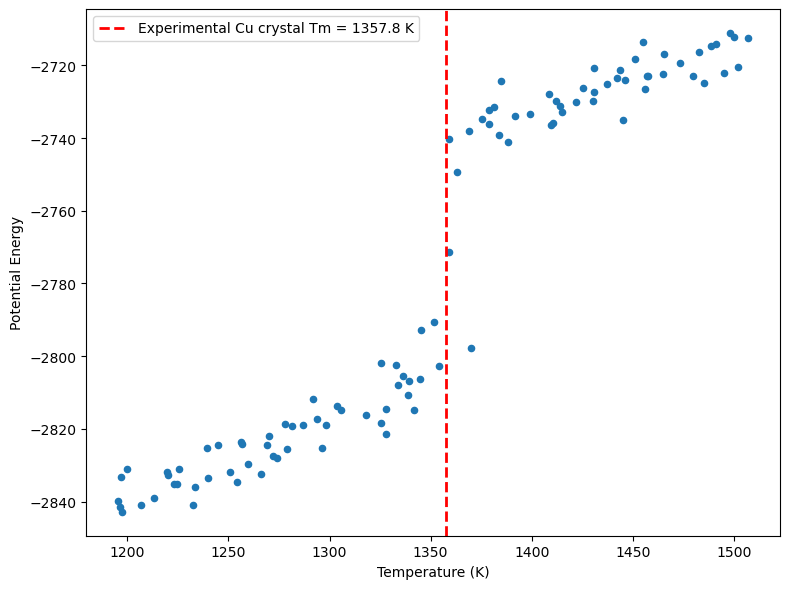

In [6]:
df = pd.read_csv("thermo-cu-melting.csv")

ax = df.plot.scatter(
    x="Temp",
    y="PotEng",
    figsize=(8, 6)
)

# Experimental melting temperature of Cu (K)
Tm_exp = 1357.77 

# Add a vertical red dashed line
ax.axvline(
    x=Tm_exp,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Experimental Cu crystal Tm = {Tm_exp:.1f} K"
)

ax.set_xlabel("Temperature (K)")
ax.set_ylabel("Potential Energy")
ax.legend()
plt.tight_layout()
plt.savefig("cu-melting.png")
plt.show()